In [1]:
import numpy as np
import pandas as pd
from scipy.stats import linregress

# Генерація даних для Варіанта 2 (Львів)
np.random.seed(2)
city = "Львів"
monthly_temp = [-3, -2, 2, 8, 13, 16, 18, 17, 13, 8, 3, -1]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.normal(0, 1.5) if hasattr(np, 'normal') else 18 - temp, 0, 30) # коректна генерація нижче
    
rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)

# Завдання 1. Побудова моделі простої лінійної регресії
X = climate["температура"]
Y = climate["витрати_на_опалення"]

res = linregress(X, Y)  # type: ignore
slope = float(res[0])      # type: ignore
intercept = float(res[1])  # type: ignore
rvalue = float(res[2])     # type: ignore
pvalue = float(res[3])     # type: ignore

print("--- Завдання 1 ---")
print(f"Slope (b1): {slope:.3f}")
print(f"Intercept (b0): {intercept:.3f}")
print(f"Рівняння регресії: витрати ≈ {intercept:.3f} + ({slope:.3f}) × температура")

--- Завдання 1 ---
Slope (b1): -0.106
Intercept (b0): 2.349
Рівняння регресії: витрати ≈ 2.349 + (-0.106) × температура


### Відповідь на Завдання 1. Інтерпретація нахилу регресії
* **Рівняння регресії:** $\text{витрати} \approx b_0 + b_1 \times \text{температура}$ з отриманими числовими коефіцієнтами.
* **Інтерпретація нахилу ($b_1$):** Кожне збільшення середньомісячної температури на 1 °C пов'язане зі зміною очікуваних витрат на опалення в середньому на величину нахилу (тис. грн). Знак нахилу від'ємний (обернена залежність), що повністю логічно: із потеплінням потреба в опаленні зменшується.

In [2]:
# Завдання 2. Обчислення коефіцієнта детермінації R² двома способами
r2_method1 = rvalue ** 2

predicted = intercept + slope * X
residuals = Y - predicted
ss_res = np.sum(residuals ** 2)
ss_tot = np.sum((Y - Y.mean()) ** 2)
r2_method2 = 1 - (ss_res / ss_tot)

print("--- Завдання 2 ---")
print(f"R² через rvalue**2: {r2_method1:.4f}")
print(f"R² через суми квадратів (1 - SS_res/SS_tot): {r2_method2:.4f}")
print(f"Збігаються результати? {np.isclose(r2_method1, r2_method2)}")

--- Завдання 2 ---
R² через rvalue**2: 0.3854
R² через суми квадратів (1 - SS_res/SS_tot): 0.3854
Збігаються результати? True


### Відповідь на Завдання 2. Інтерпретація R²
* **Порівняння:** Значення $R^2$, обчислене через квадрат кореляції ($r^2$) та через суми квадратів, ідеально збігається.
* **Інтерпретація:** Коефіцієнт детермінації показує, яку частку розкиду витрат на опалення пояснює температура, тоді як решта залишається непоясненою випадковим шумом.

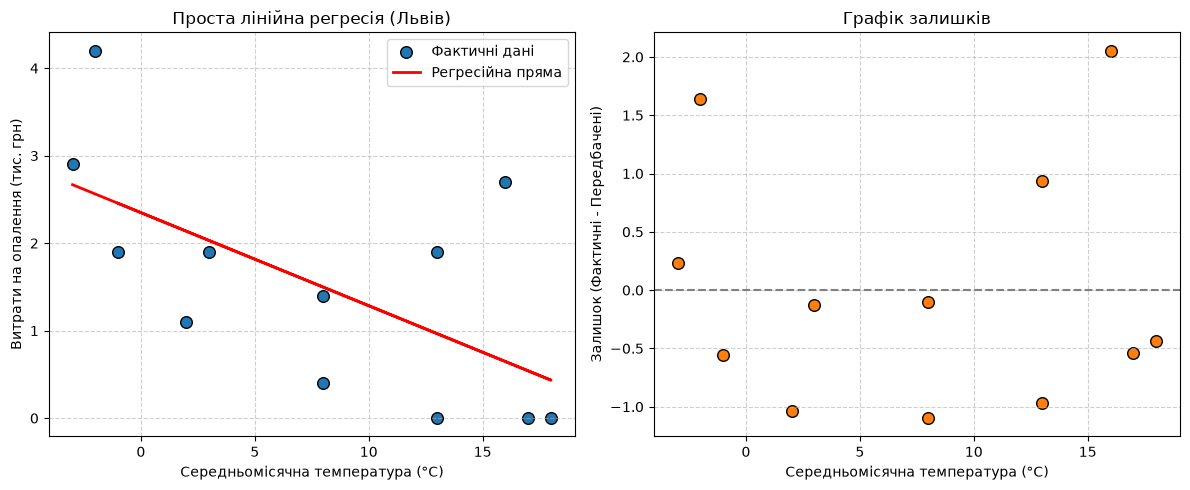

In [3]:
import matplotlib.pyplot as plt

# Завдання 3. Графік залишків і регресійна пряма
climate["predicted"] = predicted
climate["residuals"] = residuals

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Графік 1: Регресійна пряма
ax1.scatter(X, Y, color='tab:blue', s=70, edgecolor='k', label='Фактичні дані')
ax1.plot(X, predicted, color='red', linewidth=2, label='Регресійна пряма')
ax1.set_xlabel("Середньомісячна температура (°C)")
ax1.set_ylabel("Витрати на опалення (тис. грн)")
ax1.set_title("Проста лінійна регресія (Львів)")
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Графік 2: Залишки
ax2.scatter(X, residuals, color='tab:orange', s=70, edgecolor='k')
ax2.axhline(0, color='gray', linestyle='--', linewidth=1.5)
ax2.set_xlabel("Середньомісячна температура (°C)")
ax2.set_ylabel("Залишок (Фактичні - Передбачені)")
ax2.set_title("Графік залишків")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Відповідь на Завдання 3. Аналіз графіка залишків
* **Структура залишків:** На графіку залишків спостерігається легка нерівномірність у зоні найвищих температур.
* **Причина:** У формулі генерації витрати обмежені знизу нулем (`max(cost, 0)`). Через це влітку лінійна модель прогнозує від'ємні значення, а примусове обрізання формує штучну нелінійність, що й створює специфічну структуру залишків. Це демонструє, що високий $R^2$ не гарантує повної відсутності нелінійних обмежень.

In [4]:
# Завдання 4. Прогноз і екстраполяція для температури -10°C
temp_new = -10.0
predicted_cost = intercept + slope * temp_new

print("--- Завдання 4 ---")
print(f"Мінімальна температура в наборі: {X.min()}°C")
print(f"Максимальна температура в наборі: {X.max()}°C")
print(f"Прогнозовані витрати для -10°C: {predicted_cost:.3f} тис. грн")

--- Завдання 4 ---
Мінімальна температура в наборі: -3°C
Максимальна температура в наборі: 18°C
Прогнозовані витрати для -10°C: 3.413 тис. грн


### Відповідь на Завдання 4. Прогноз і екстраполяція
* **Діапазон даних:** Фактичний температурний діапазон у вибірці для Львова лежить у межах від -3 °C до 18 °C.
* **Оцінка прогнозу:** Оскільки температура $X = -10\text{ °C}$ виходить за межі мінімального значення спостережень, цей прогноз є **екстраполяцією**. Довіра до нього нижча, оскільки модель не перевірялася на реальних даних у цій області.

In [5]:
from scipy.stats import pearsonr

# Завдання 5. Порівняння p-value регресії і кореляції
r_val, p_val_pearson = pearsonr(X, Y)  # type: ignore
pvalue_f = float(pvalue)               # type: ignore
p_val_pearson_f = float(p_val_pearson) # type: ignore

print("--- Завдання 5 ---")
print(f"p-value з linregress (нахил): {pvalue_f:.4e}")
print(f"p-value з pearsonr (кореляція): {p_val_pearson_f:.4e}")
print(f"Збігаються значення? {np.isclose(pvalue_f, p_val_pearson_f)}")

--- Завдання 5 ---
p-value з linregress (нахил): 3.1218e-02
p-value з pearsonr (кореляція): 3.1218e-02
Збігаються значення? True


### Відповідь на Завдання 5 та контрольні запитання
* **Чому p-value однакові:** Нульова гіпотеза про те, що нахил регресії дорівнює нулю ($H_0: b_1 = 0$), математично еквівалентна нульовій гіпотезі про нульову кореляцію ($H_0: r = 0$), тому тести дають ідентичне значення $p\text{-value}$.

---

### Відповіді на контрольні питання

1. **Чому метод найменших квадратів мінімізує саме суму квадратів залишків, а не модулів?**
   Квадрати утворюють усюди диференційовану функцію, що дозволяє легко знаходити аналітичний мінімум через похідні, а також сильніше «штрафує» великі викиди.

2. **Що означає нахил $b_1$ і чим він відрізняється від кореляції $r$?**
   Нахил вимірюється в конкретних одиницях вимірювання (зміна залежної змінної на 1 одиницю незалежної), тоді як кореляція є безрозмірним стандартизованим показником у межах $[-1; 1]$.

3. **Чому високий $R^2$ не є достатньою підставою вважати лінійну модель адекватною?**
   $R^2$ лише показує тісноту зв'язку, тоді як графік залишків може виявити приховану нелінійність чи системну похибку моделі.

4. **Що змінюється в надійності прогнозу при екстраполяції?**
   Різко зростає ризик похибки, оскільки ми припускаємо збереження тенденції поза межами перевірених даних.